# **Vanilla Autoencoder**

**Project question.** How well does a plain autoencoder, trained on benign traffic only, detect attacks compared with the PCA baseline (F1 = 0.761)?

The model compresses each row of 40 traffic features into a small bottleneck and reconstructs it. It only ever sees benign traffic, so it learns to reconstruct normal behaviour well. The anomaly score of a row is its reconstruction error (MSE): attacks do not follow the patterns the model learned, so their error is high.

In [1]:
import os
if not os.path.exists("iomt-anomaly-detection"):
    !git clone -q https://github.com/JanaAlzobidi/iomt-anomaly-detection.git
try:
    import keras_tuner
except ImportError:
    !pip -q install keras-tuner

In [2]:
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
import keras_tuner as kt
from keras import layers

REPO = "iomt-anomaly-detection"
DATA_DIR = f"{REPO}/data"
RESULTS_DIR = f"{REPO}/results"
MODEL_DIR = f"{REPO}/models/dense_ae"
sys.path.insert(0, REPO)
from evaluate import (load_data, reconstruction_errors, per_feature_errors,
                      evaluate, compare_percentiles)

SEED = 42
keras.utils.set_random_seed(SEED)

X_train, X_val, X_test, y_test, attack_test = load_data(DATA_DIR)
FEATURES = json.load(open(f"{DATA_DIR}/config.json"))["features"]
INPUT_DIM = X_train.shape[1]
BATCH_SIZE = 512

X_train (150000, 40) (benign only) | X_val (30000, 40) (benign only) | X_test (42893, 40), attacks: 5286 (12.3%)


## **1. Model design**

A symmetric fully connected autoencoder:

`40 → hidden layer(s) → bottleneck ("latent") → hidden layer(s) → 40`

- **ReLU** in the hidden layers, **linear** output: the inputs are scaled to [0, 1] on benign training data, but attack values can be far outside that range, and a linear output does not hide that.
- **Regularization:** L2 weight penalty on every hidden layer, Dropout after the first encoder layer, and Early Stopping on the validation reconstruction error.

In [3]:
def build_autoencoder(latent, width, n_hidden, dropout, l2, lr, latent_activation="relu"):
    # L2 penalty that we add to every hidden layer
    reg = keras.regularizers.L2(l2)

    # sizes of the hidden layers
    if n_hidden == 1:
        widths = [width]
    else:
        widths = [width, width // 2]

    inputs = keras.Input(shape=(INPUT_DIM,), name="traffic_features")
    x = inputs

    # encoder
    for i in range(len(widths)):
        x = layers.Dense(widths[i], activation="relu",
                         kernel_regularizer=reg, name=f"enc_{i+1}")(x)
        # dropout only after the first layer
        if i == 0:
            x = layers.Dropout(dropout, name="dropout")(x)

    # bottleneck ("relu" or "linear" is chosen by the tuner)
    x = layers.Dense(latent, activation=latent_activation,
                     kernel_regularizer=reg, name="latent")(x)

    # decoder (same layers as the encoder but in reverse order)
    decoder_widths = widths[::-1]
    for i in range(len(decoder_widths)):
        x = layers.Dense(decoder_widths[i], activation="relu",
                         kernel_regularizer=reg, name=f"dec_{i+1}")(x)

    # linear output because attack values can be bigger than 1 after scaling
    outputs = layers.Dense(INPUT_DIM, activation="linear", name="reconstruction")(x)

    model = keras.Model(inputs, outputs, name="vanilla_autoencoder")

    # the loss is MSE + the L2 penalty
    # I also track "mse" as a metric to see the reconstruction error alone
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss="mse", metrics=["mse"])
    return model

## **2. Hyperparameter tuning (Keras Tuner)**

Bayesian optimization, 25 trials of at most 25 epochs each.

**Objective: `val_mse`**, the reconstruction error on benign validation data. Validation contains no attacks and the test set is never used here, so the choice of architecture cannot leak any information about the attacks.

In [4]:
def build_from_hp(hp):
    # the tuner picks one value for each hyperparameter from these lists
    latent = hp.Choice("latent", [8, 16, 32])
    width = hp.Choice("width", [32, 48, 64, 128])
    n_hidden = hp.Choice("n_hidden", [1, 2])
    dropout = hp.Choice("dropout", [0.0, 0.05, 0.1])
    l2 = hp.Choice("l2", [1e-6, 1e-5, 1e-4])
    lr = hp.Choice("lr", [5e-4, 1e-3, 3e-3])
    latent_activation = hp.Choice("latent_activation", ["relu", "linear"])
    return build_autoencoder(latent, width, n_hidden, dropout, l2, lr, latent_activation)

# Bayesian optimization (uses the results of earlier trials to pick the next one)
tuner = kt.BayesianOptimization(
    build_from_hp,
    objective=kt.Objective("val_mse", direction="min"),
    max_trials=25,
    seed=SEED,
    overwrite=True,              # start a fresh search every time
    directory="tuning",
    project_name="vanilla_ae",
)

# stop a trial early if val_mse does not improve for 3 epochs
stop_early = keras.callbacks.EarlyStopping(monitor="val_mse", patience=3)

# input and target are the same (X_train) because the model reconstructs its input
tuner.search(
    X_train, X_train,
    validation_data=(X_val, X_val),
    epochs=25,
    batch_size=BATCH_SIZE,
    callbacks=[stop_early],
    verbose=0,
)

# collect all trials in a table, best one first
rows = []
for trial in tuner.oracle.trials.values():
    row = dict(trial.hyperparameters.values)
    row["val_mse"] = trial.score
    rows.append(row)

tuning_table = pd.DataFrame(rows).sort_values("val_mse").reset_index(drop=True)
print(tuning_table.to_string())

    latent  width  n_hidden  dropout        l2      lr latent_activation   val_mse
0       32     48         1     0.00  0.000001  0.0005            linear  0.000033
1       32     64         1     0.00  0.000001  0.0030            linear  0.000051
2       32    128         1     0.00  0.000010  0.0005              relu  0.000081
3       16     48         1     0.00  0.000001  0.0030            linear  0.000086
4       32     32         1     0.00  0.000001  0.0005              relu  0.000087
5       16    128         1     0.00  0.000010  0.0010            linear  0.000102
6       16     48         1     0.05  0.000001  0.0030            linear  0.000153
7       32     64         1     0.05  0.000001  0.0030            linear  0.000217
8        8    128         1     0.00  0.000001  0.0005              relu  0.000287
9       32     32         2     0.00  0.000001  0.0010            linear  0.000360
10      16     32         2     0.00  0.000001  0.0005              relu  0.000371
11  

## **3. Final training**

The best configuration is retrained from scratch for up to 200 epochs. Early Stopping (patience 10) stops training when the validation error no longer improves and restores the best weights. The learning rate is halved whenever the validation error is stuck for 4 epochs.

In [5]:
best_hp = tuner.get_best_hyperparameters(1)[0].values
print("Best hyperparameters:", best_hp)

keras.utils.set_random_seed(SEED)
model = build_autoencoder(**best_hp)
model.summary()

# stop when validation stops improving and go back to the best weights
early_stop = keras.callbacks.EarlyStopping(monitor="val_mse", patience=10, restore_best_weights=True)
# halve the learning rate when validation is stuck, to fine-tune the weights
reduce_lr = keras.callbacks.ReduceLROnPlateau(monitor="val_mse", factor=0.5, patience=4, min_lr=1e-5)

history = model.fit(
    X_train, X_train, validation_data=(X_val, X_val),
    epochs=200, batch_size=BATCH_SIZE, callbacks=[early_stop, reduce_lr], verbose=0,
).history
best_epoch = int(np.argmin(history["val_mse"])) + 1
print(f"Trained {len(history['val_mse'])} epochs | best epoch {best_epoch} | "
      f"best val_mse {min(history['val_mse']):.6g}")

Best hyperparameters: {'latent': 32, 'width': 48, 'n_hidden': 1, 'dropout': 0.0, 'l2': 1e-06, 'lr': 0.0005, 'latent_activation': 'linear'}


Model: "vanilla_autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ traffic_features (InputLayer)   │ (None, 40)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_1 (Dense)                   │ (None, 48)             │         1,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 48)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent (Dense)                  │ (None, 32)             │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_1 (Dense)                   │ (None, 48)             │         1,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reconstruction (Dense)          │ (None, 40)             │         1,960 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,080 (27.66 KB)

 Trainable params: 7,080 (27.66 KB)

 Non-trainable params: 0 (0.00 B)

Trained 200 epochs | best epoch 200 | best val_mse 2.38091e-05


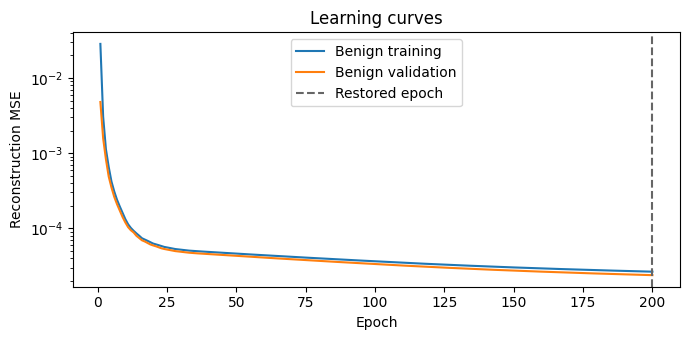

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ep = range(1, len(history["mse"]) + 1)
ax.plot(ep, history["mse"], label="Benign training")
ax.plot(ep, history["val_mse"], label="Benign validation")
ax.axvline(best_epoch, color="0.4", ls="--", label="Restored epoch")
ax.set(xlabel="Epoch", ylabel="Reconstruction MSE", yscale="log", title="Learning curves")
ax.legend(); plt.tight_layout(); plt.show()

## **4. Evaluation**

Shared evaluation used by every model: the threshold is the 99th percentile of the benign validation scores, so no attack label is used to set it.


===== Vanilla AE =====
Threshold (P99 of validation scores): 0.000249238
          roc_auc: 0.9550
           pr_auc: 0.9026
               f1: 0.8881
        precision: 0.9338
           recall: 0.8466
 false_alarm_rate: 0.0084

Confusion matrix (rows = true, cols = predicted)
        Benign  Attack
Benign   37290     317
Attack     811    4475

Recall per attack type (weakest first):
                           n recall
type                               
ARP Spoofing             300  0.023
MQTT Malformed Data      300  0.240
Recon VulScan            300  0.470
Recon PingSweep          186  0.522
Recon OSScan             300  0.890
Recon PortScan           300  0.970
DDoS TCP Flood           300  1.000
DoS SYN Flood            300  1.000
DoS ICMP Flood           300  1.000
DoS TCP Flood            300  1.000
DoS UDP Flood            300  1.000
MQTT DDoS Publish Flood  300  1.000
DDoS UDP Flood           300  1.000
DDoS ICMP Flood          300  1.000
DDoS SYN Flood           300  1.00

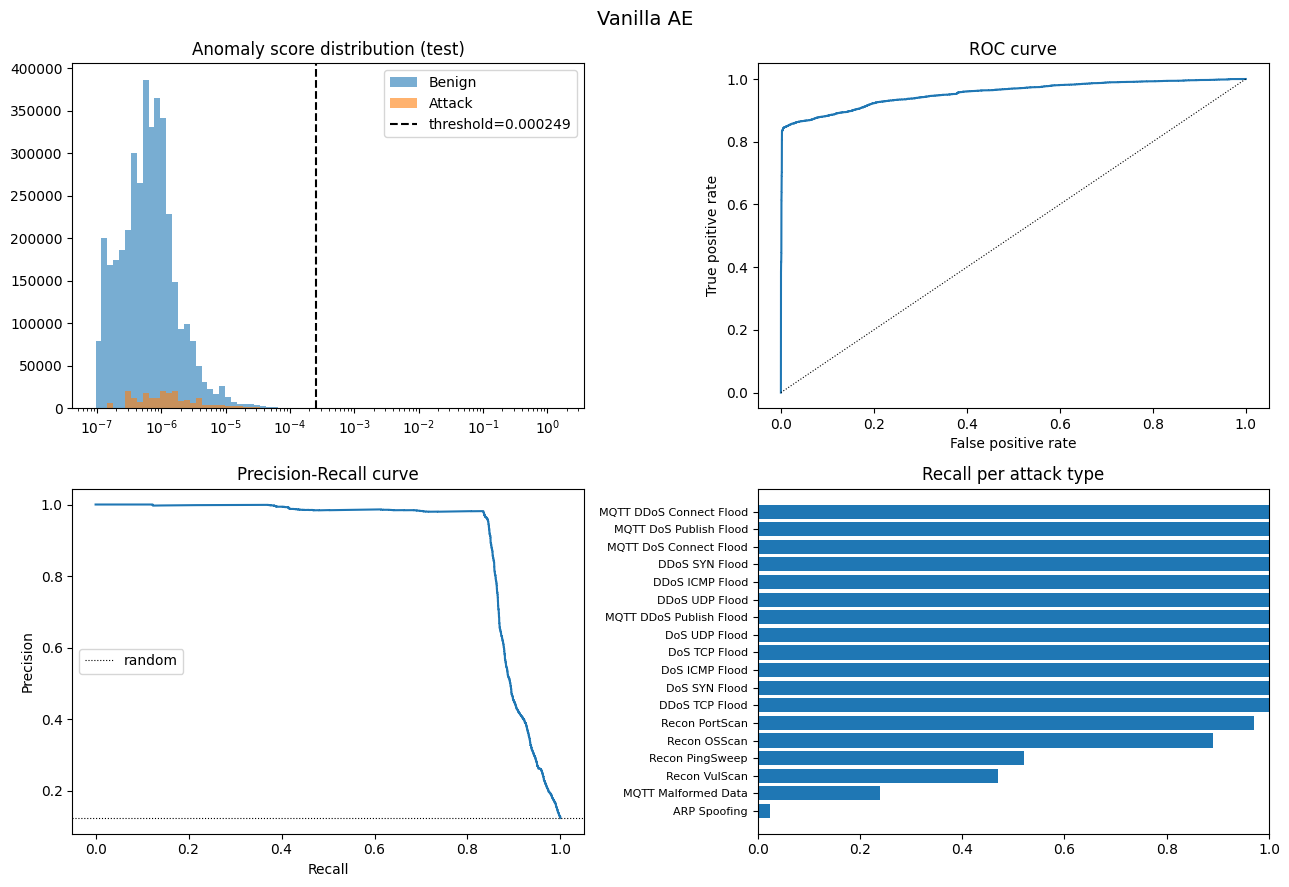


Saved to iomt-anomaly-detection/results/results.csv


In [7]:
val_scores = reconstruction_errors(model, X_val)
test_scores = reconstruction_errors(model, X_test)
res = evaluate(test_scores, y_test, attack_test, val_scores,
               model_name="Vanilla AE", person="1", save_dir=RESULTS_DIR)

In [8]:
compare_percentiles(test_scores, y_test, val_scores);

 percentile  threshold     f1  recall  false_alarm_rate
    95.0000     0.0001 0.7555  0.8685            0.0605
    99.0000     0.0002 0.8881  0.8466            0.0084
    99.5000     0.0005 0.8975  0.8396            0.0044


## **5. Comparison with the PCA baseline**

PCA is the linear version of an autoencoder, so this comparison shows what the non-linear model adds. The PCA baseline is recomputed here with the same settings as `models/baselines/pca_baseline.ipynb` to get its recall per attack type.

In [9]:
from sklearn.decomposition import PCA

pca = PCA(n_components=0.95, random_state=SEED).fit(X_train)
pca_err = lambda X: np.mean((X - pca.inverse_transform(pca.transform(X))) ** 2, axis=1)
_stdout = sys.stdout; sys.stdout = open(os.devnull, "w")       # keep the output short
pca_res = evaluate(pca_err(X_test), y_test, attack_test, pca_err(X_val),
                   model_name="Baseline: PCA", plot=False)
sys.stdout = _stdout

metrics = ["roc_auc", "pr_auc", "f1", "precision", "recall", "false_alarm_rate"]
summary = pd.DataFrame({"PCA baseline": [pca_res[m] for m in metrics],
                        "Vanilla AE": [res[m] for m in metrics]}, index=metrics)
summary["difference"] = summary["Vanilla AE"] - summary["PCA baseline"]
summary.round(4)

,PCA baseline,Vanilla AE,difference
roc_auc,0.9380,0.9550,0.0170
pr_auc,0.8347,0.9026,0.0679
f1,0.7614,0.8881,0.1267
precision,0.9594,0.9338,-0.0256
recall,0.6311,0.8466,0.2155
false_alarm_rate,0.0037,0.0084,0.0047


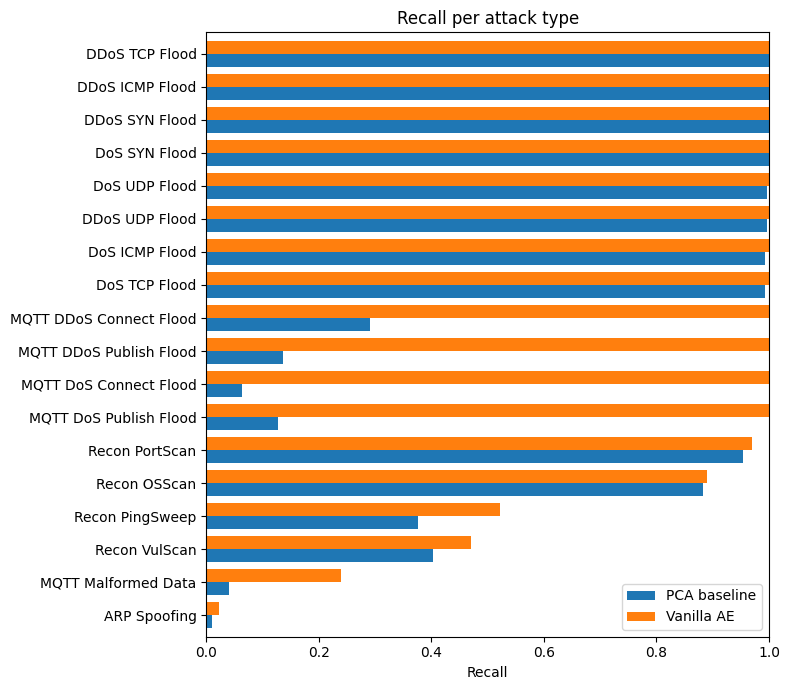

,PCA baseline,Vanilla AE
ARP Spoofing,0.010,0.023
MQTT Malformed Data,0.040,0.240
Recon VulScan,0.403,0.470
Recon PingSweep,0.376,0.522
Recon OSScan,0.883,0.890
Recon PortScan,0.953,0.970
MQTT DoS Publish Flood,0.127,1.000
MQTT DoS Connect Flood,0.063,1.000
MQTT DDoS Publish Flood,0.137,1.000
MQTT DDoS Connect Flood,0.290,1.000


In [10]:
per_attack = pd.DataFrame({"PCA baseline": pca_res["per_attack_recall"],
                           "Vanilla AE": res["per_attack_recall"]}).sort_values("Vanilla AE")
ax = per_attack.plot.barh(figsize=(8, 7), width=0.8)
ax.set(xlabel="Recall", xlim=(0, 1), title="Recall per attack type")
plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/figures/vanilla_ae_vs_pca.png", dpi=120); plt.show()
per_attack.round(3)

The figure shows per-attack Recall for both models. Both detect volumetric flooding attacks (DoS/DDoS) almost perfectly, since these deviate clearly from normal traffic. The key difference is in MQTT Flood: PCA's recall is only 0.06–0.29, while the Autoencoder's approaches 1.0. This suggests these attacks are not linearly separable from normal traffic, so the AE's non-linear representation is needed to catch them. Both models perform poorly on ARP Spoofing and MQTT Malformed Data. This likely reflects a lack of discriminative information in the features rather than a limitation of the models.

## **6. Save and load**

The model is saved together with the threshold and the hyperparameters, since all three are needed at inference time. The reloaded model must give exactly the same scores.

In [11]:
os.makedirs(MODEL_DIR, exist_ok=True)
MODEL_PATH = f"{MODEL_DIR}/vanilla_ae.keras"
META_PATH = f"{MODEL_DIR}/vanilla_ae_metadata.json"

model.save(MODEL_PATH)
json.dump({"threshold": res["threshold"], "percentile": res["percentile"],
           "features": FEATURES, "hyperparameters": best_hp,
           },
          open(META_PATH, "w"), indent=2)

loaded_model = keras.models.load_model(MODEL_PATH)
meta = json.load(open(META_PATH))
np.testing.assert_allclose(reconstruction_errors(loaded_model, X_test), test_scores, rtol=1e-5, atol=1e-8)
print(f"Reloaded model reproduces the scores of all {len(X_test):,} test rows.")

Reloaded model reproduces the scores of all 42,893 test rows.


## **7. Inference**

`predict(X)` takes prepared rows (40 features, same order and scaling as `X_test`) and returns for each row:

- `score`: the reconstruction error
- `is_anomaly`: whether the score is above the saved threshold
- `top_features`: the 3 features with the largest reconstruction error, i.e. what looked abnormal in this row

In [12]:
THRESHOLD = meta["threshold"]
feature_names = np.array(meta["features"])

def predict(X):
    X = np.asarray(X, dtype="float32")
    if X.ndim == 1:
        X = X.reshape(1, -1)
    if X.shape[1] != len(feature_names):
        raise ValueError(f"expected {len(feature_names)} features, got {X.shape[1]}")
    err = per_feature_errors(loaded_model, X)
    scores = err.mean(axis=1)
    top = np.argsort(-err, axis=1)[:, :3]
    return [{"score": float(s), "is_anomaly": bool(s > THRESHOLD),
             "top_features": feature_names[t].tolist()} for s, t in zip(scores, top)]

rng = np.random.default_rng(SEED)
idx = np.concatenate([rng.choice(np.flatnonzero(y_test == 0), 3, replace=False),
                      rng.choice(np.flatnonzero(y_test == 1), 3, replace=False)])
demo = pd.DataFrame(predict(X_test[idx]))
demo.insert(0, "true_type", attack_test[idx])
demo

,true_type,score,is_anomaly,top_features
0,Benign,5.840358e-07,False,"[avg, tot_sum, magnitue]"
1,Benign,1.010664e-06,False,"[magnitue, tot_sum, avg]"
2,Benign,4.439914e-06,False,"[magnitue, fin_flag_number, tot_sum]"
3,MQTT Malformed Data,1.207241e-06,False,"[tot_sum, radius, fin_flag_number]"
4,DoS SYN Flood,7.575765e-03,True,"[ack_flag_number, tcp, udp]"
5,Recon PortScan,1.509074e-02,True,"[rst_flag_number, ack_flag_number, syn_flag_nu..."
